# 94 · Bin-count sweep and distribution-shift clipping

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
from vlacourse import list_episodes, load_episode

DATA = os.path.abspath("../data/tabletop_panda_v1")

class Tok:
    def __init__(self, data, n_bins=256, lo=1, hi=99):
        self.lo, self.hi, self.n = np.percentile(data, lo, 0), np.percentile(data, hi, 0), n_bins
        self.hi = np.where(self.hi - self.lo < 1e-8, self.lo + 1e-8, self.hi)
    def roundtrip(self, x):
        ids = (np.clip((x - self.lo) / (self.hi - self.lo), 0, 1 - 1e-6) * self.n).astype(int)
        return (ids + 0.5) / self.n * (self.hi - self.lo) + self.lo

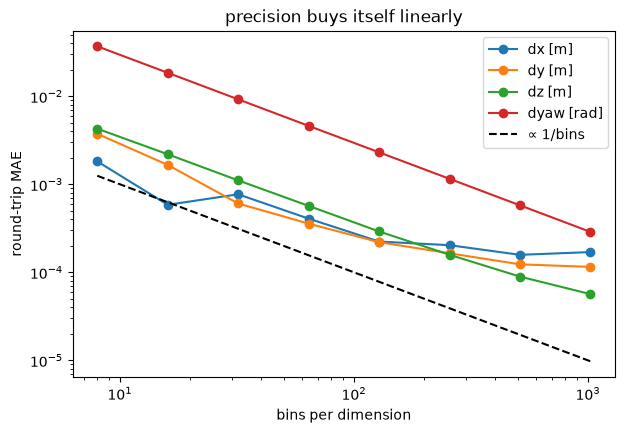

In [2]:
eps = [load_episode(p)["action"] for p in list_episodes(DATA)]
A = np.concatenate(eps)
bins = [8, 16, 32, 64, 128, 256, 512, 1024]
mae = np.array([np.abs(Tok(A, b).roundtrip(A) - A).mean(0) for b in bins])
plt.figure(figsize=(7, 4.5))
for i, name in [(0, "dx [m]"), (1, "dy [m]"), (2, "dz [m]"), (5, "dyaw [rad]")]:
    plt.loglog(bins, mae[:, i], "o-", label=name)
plt.loglog(bins, 0.01 / np.array(bins), "k--", label="∝ 1/bins")
plt.xlabel("bins per dimension"); plt.ylabel("round-trip MAE"); plt.legend(); plt.title("precision buys itself linearly"); plt.show()

In [3]:
counts = [np.bincount((np.clip((A[:, 0] - Tok(A, b).lo[0]) / (Tok(A, b).hi[0] - Tok(A, b).lo[0]), 0, 1 - 1e-6) * b).astype(int), minlength=b) for b in bins]
print("examples per used bin (dx), i.e. training signal per class:")
for b, c in zip(bins, counts):
    print(f"  {b:5d} bins: median {np.median(c[c > 0]):7.0f} examples per non-empty bin, {np.mean(c == 0):.0%} of bins empty")

examples per used bin (dx), i.e. training signal per class:
      8 bins: median     370 examples per non-empty bin, 0% of bins empty
     16 bins: median     158 examples per non-empty bin, 0% of bins empty
     32 bins: median      94 examples per non-empty bin, 0% of bins empty
     64 bins: median      50 examples per non-empty bin, 3% of bins empty
    128 bins: median      25 examples per non-empty bin, 13% of bins empty
    256 bins: median      12 examples per non-empty bin, 27% of bins empty
    512 bins: median       9 examples per non-empty bin, 44% of bins empty
   1024 bins: median       7 examples per non-empty bin, 61% of bins empty


tokenizer fit on SLOW episodes: in-distribution MAE 0.136 mm, on FAST episodes 0.546 mm; 8.6% of fast translation values clipped


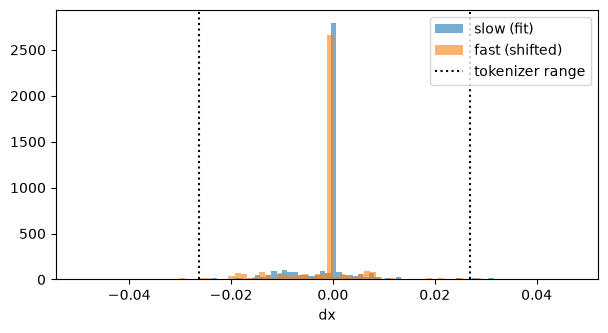

In [4]:
speed = np.array([np.linalg.norm(e[:, :3], axis=1).mean() for e in eps])
slow = np.concatenate([e for e, s in zip(eps, speed) if s < np.median(speed)])
fast = np.concatenate([e for e, s in zip(eps, speed) if s >= np.median(speed)])
tok_slow = Tok(slow, 256)
mae_in = np.abs(tok_slow.roundtrip(slow) - slow)[:, :3].mean() * 1000
mae_out = np.abs(tok_slow.roundtrip(fast) - fast)[:, :3].mean() * 1000
sat = np.mean((fast[:, :3] > tok_slow.hi[:3]) | (fast[:, :3] < tok_slow.lo[:3]))
print(f"tokenizer fit on SLOW episodes: in-distribution MAE {mae_in:.3f} mm, on FAST episodes {mae_out:.3f} mm; {sat:.1%} of fast translation values clipped")
plt.figure(figsize=(7, 3.5)); plt.hist(slow[:, 0], 80, alpha=0.6, label="slow (fit)"); plt.hist(fast[:, 0], 80, alpha=0.6, label="fast (shifted)")
plt.axvline(tok_slow.lo[0], c="k", ls=":"); plt.axvline(tok_slow.hi[0], c="k", ls=":", label="tokenizer range"); plt.legend(); plt.xlabel("dx"); plt.show()